# Experiment 1 · Notebook 09: Summary

*J26-IT-304 PP1. Baseline confusion classifier (TF-IDF + Logistic Regression). Section 15. Slide-ready (PP1 slide 6, "Experiment Results").*

This notebook **computes nothing new**. It reads only committed files (`models/clf-v1.0.0/metadata.json`, `reports/experiments/*.csv` and `*.png`),
checks them against the metadata, and presents the result. Numbers that appear only in an earlier notebook's printed output carry a citation such as *(notebook 04 §9)*.

Section numbers run continuously across the Experiment 1 series, so a reference such as "EDA §3.5" or "section 8" points to the same place in every notebook:

| Notebook | Sections | Stage |
|---|---|---|
| `01_data_and_eda` | §1-§3 | provenance, load, exploratory analysis, leakage demonstration |
| `02_cleaning_and_labels` | §4-§5 | deduplication, group key, label mapping, proxy caveat |
| `03_split_and_baselines` | §6-§7 | group-aware split, trivial baselines, frozen OOD probe |
| `04_model_training_and_evaluation` | §8-§9 | TF-IDF + LR, group-aware CV, the single test evaluation |
| `05_features_and_ood_probe` | §10-§11 | coefficient inspection, stability, length, OOD probe evaluation |
| `06_sensitivity_check` | §12 | robustness of the label mapping: Partial Correct dropped |
| `07_publish_artifact` | §13 | the `clf-v1.0.0` artifact: pipeline, metadata, rules, verification |
| `08_error_analysis` | §14 | error analysis, blind judging with a control sample, motivation for Experiment 2 |
| `09_summary` | §15 | slide-ready summary of the whole experiment |

Each notebook runs on its own from a clean kernel (kernel `exp1-confusion`). Run them in order 01 → 09 to regenerate every file in `reports/experiments/`.

**Setup.** Loads the committed files and **asserts them against the published metadata**, so every table below is of the model that is served. A second check
asserts the numbers quoted in the prose against these files. Nothing is recomputed from data and nothing is retrained.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

from confusion_baseline import MODELS_DIR, REPORTS_DIR

R = REPORTS_DIR / "experiments"
meta = json.loads((MODELS_DIR / "clf-v1.0.0" / "metadata.json").read_text(encoding="utf-8"))
cmp_ = pd.read_csv(R / "comparison_primary.csv").set_index("System")
probe_cat = pd.read_csv(R / "probe_per_category_primary.csv")
probe_all = pd.read_csv(R / "probe_overall_primary.csv").set_index("System")
side = pd.read_csv(R / "sensitivity_side_by_side.csv").set_index("mapping")
esum = pd.read_csv(R / "error_summary.csv")
pd.set_option("display.width", 200)

col = {"accuracy": "Accuracy", "precision_confused": "Precision", "recall_confused": "Recall", "f1_confused": "F1 (confused)", "macro_f1": "Macro F1"}
for k, c in col.items():
    assert round(meta["metrics"][k], 4) == round(float(cmp_.loc["TF-IDF + LR", c]), 4), k
b = meta["baselines"]
assert round(b["majority_f1_confused"], 4) == float(cmp_.loc["Majority class", "F1 (confused)"])
assert round(b["length_only_macro_f1"], 4) == float(cmp_.loc["Length-only LR", "Macro F1"])
assert round(b["random_f1_confused"], 4) == float(cmp_.loc["Stratified random (seed 42)", "F1 (confused)"])
po = probe_all.loc["TF-IDF + LR"]
assert round(meta["ood_probe"]["accuracy"], 4) == float(po["Accuracy"]) and round(meta["ood_probe"]["specificity_understood"], 4) == float(po["Specificity"])
assert round(meta["sensitivity_drop_partial"]["macro_f1"], 4) == float(side.loc["drop_partial (a) primary config", "macro F1"])
assert round(meta["sensitivity_drop_partial"]["f1_confused"], 4) == float(side.loc["drop_partial (a) primary config", "F1(confused)"])
print(f"PASS: committed CSVs agree with {meta['version']} metadata (test metrics, baselines, probe, sensitivity)")

# counts used in the prose, read from the committed error summary
def n_of(group, category, kind="multi-label"):
    r = esum[(esum["kind"] == kind) & (esum["group"] == group) & (esum["category"] == category)].iloc[0]
    return int(r["n"]), int(r["group_size"])
assert n_of("errors (all)", "needs_context") == (8, 67) and n_of("control", "needs_context") == (2, 67)
n_fp, n_fn = n_of("FP", "short")[1], n_of("FN", "short")[1]
assert (n_fp, n_fn) == (43, 24)
rec = meta["metrics"]["recall_confused"]
tp = round(n_fn * rec / (1 - rec))                       # recall = TP / (TP + FN)
tn = meta["split"]["test_rows"] - tp - n_fp - n_fn
assert (tp, tn) == (105, 44)
print(f"PASS: error summary and metadata imply TP {tp} | FP {n_fp} | FN {n_fn} | TN {tn} on {meta['split']['test_rows']} test rows")

PASS: committed CSVs agree with clf-v1.0.0 metadata (test metrics, baselines, probe, sensitivity)
PASS: error summary and metadata imply TP 105 | FP 43 | FN 24 | TN 44 on 216 test rows


## 15.0 Read this first: the proxy caveat

**I built this baseline on a proxy: the label is answer correctness, and correctness is not confusion.** The data is a synthetic set of generated answers with no hedging and no real student phrasing, so a model trained on it has never seen the messages the tutor will actually receive.
**The out-of-distribution probe quantifies that gap** (section 15.3): on 40 hand-written student messages the model flags 34 of 40 as confused.

## 15.1 Headline comparison

**Why.** A raw F1 means nothing without the trivial strategies beside it. With 60% of answers "confused", always answering "confused" already scores F1(confused) 0.75, so the claim is the **margin**.
Test set: 216 answers from 72 questions the model never saw. Threshold 0.5.

In [2]:
head = cmp_.loc[["Majority class", "Stratified random (seed 42)", "Length-only LR", "TF-IDF + LR"]].round(4)
display(head)

,Accuracy,Precision,Recall,F1 (confused),Macro F1
System,,,,,
Majority class,0.5972,0.5972,1.0000,0.7478,0.3739
Stratified random (seed 42),0.4583,0.5441,0.5736,0.5585,0.4289
Length-only LR,0.6759,0.6746,0.8837,0.7651,0.6214
TF-IDF + LR,0.6898,0.7095,0.8140,0.7581,0.6629


**Margins of TF-IDF + LR, with 95% intervals** from a cluster bootstrap over the 72 test questions, 1000 resamples *(notebook 04 §9)*:

| | F1 (confused) | Macro F1 |
|---|---|---|
| vs **majority** (always confused) | +0.010 [-0.035, +0.056], includes 0 | **+0.289 [+0.222, +0.356]**, excludes 0 |
| vs **length-only LR** | -0.007 [-0.066, +0.053], includes 0 | +0.042 [-0.060, +0.147], includes 0 |

**Reading.** The model separates the two classes far better than always answering "confused" (macro F1 0.663 vs 0.374), but on F1(confused) it is indistinguishable from it, and the data cannot show that
the words add anything beyond how long the answer is. Macro F1 95% interval for the model: 0.595 to 0.731 *(notebook 04 §9)*.

In [3]:
m, mj, ln = meta["metrics"], cmp_.loc["Majority class"], cmp_.loc["Length-only LR"]
assert round(m["f1_confused"] - float(mj["F1 (confused)"]), 3) == 0.010 and round(m["macro_f1"] - float(mj["Macro F1"]), 3) == 0.289
assert round(m["f1_confused"] - float(ln["F1 (confused)"]), 3) == -0.007 and round(m["macro_f1"] - float(ln["Macro F1"]), 3) == 0.042
print("PASS: the margins quoted above equal the differences of the committed comparison table")

PASS: the margins quoted above equal the differences of the committed comparison table


## 15.2 Confusion matrix

**Why.** The matrix shows *what kind* of mistakes the F1 hides: the model recovers most confused answers but calls about half of the understood ones confused.

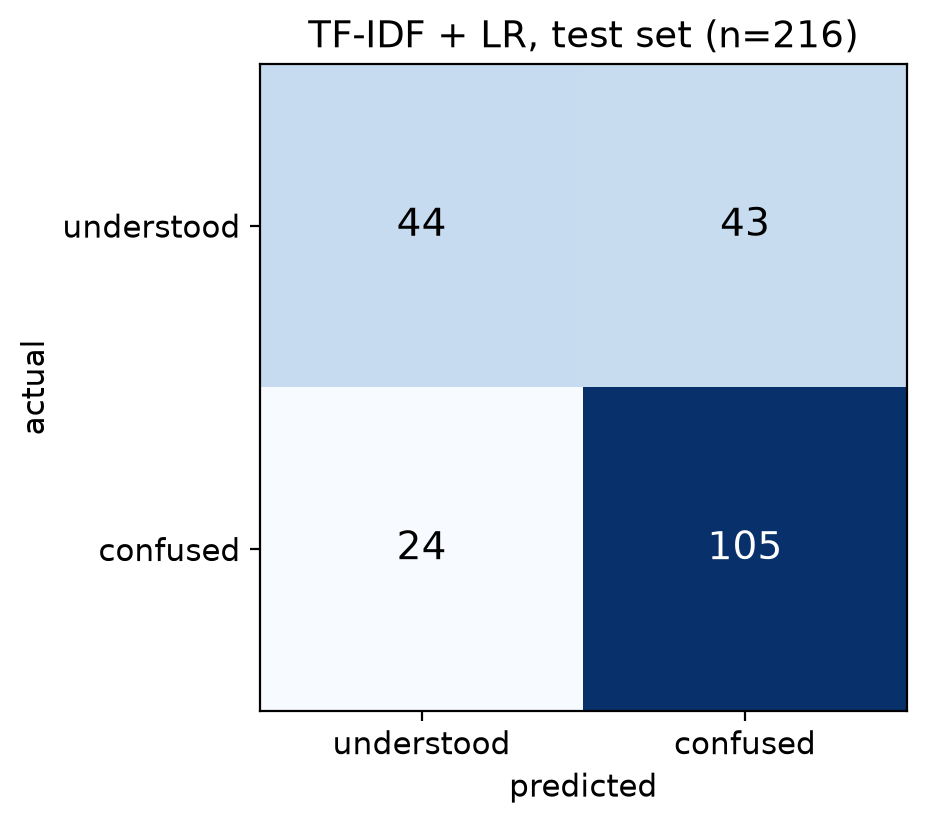

TP = 105 (confused, called confused) | FP = 43 (understood, called confused) | FN = 24 (confused, called understood) | TN = 44 (understood, called understood)
recall(confused) = 0.814 | recall(understood) = 0.506   (counts derived from the committed files; notebook 04 §9)


In [4]:
display(Image(filename=str(R / "fig_confusion_matrix_primary.png"), width=420))
print(f"TP = {tp} (confused, called confused) | FP = {n_fp} (understood, called confused) | FN = {n_fn} (confused, called understood) | TN = {tn} (understood, called understood)")
print(f"recall(confused) = {rec:.3f} | recall(understood) = {tn / (tn + n_fp):.3f}   (counts derived from the committed files; notebook 04 §9)")

## 15.3 The out-of-distribution probe

**Why.** 40 hand-written student-style messages, frozen before any model existed (`probe/ood_probe.yaml`), never used for training. It is 3 : 1 towards confused, so "always confused" scores accuracy 0.75 on it and accuracy alone is never quoted.

In [5]:
display(probe_cat[["category", "expected", "n", "model correct", "model rate", "length-only rate", "mean P(confused)", "rate means"]])
display(probe_all.round(4))

,category,expected,n,model correct,model rate,length-only rate,mean P(confused),rate means
0,explicit_confusion,confused,10,9,0.9,1.0,0.823,recall
1,topic_confusion,confused,10,9,0.9,1.0,0.757,recall
2,hedged_attempt,confused,10,8,0.8,1.0,0.829,recall
3,explicit_understanding,understood,10,2,0.2,0.0,0.694,specificity


,Accuracy,Precision,Recall (confused),Specificity,Balanced acc.,F1 (confused),Macro F1
System,,,,,,,
Always confused,0.75,0.7500,1.0000,0.0,0.5000,0.8571,0.4286
Length-only LR,0.75,0.7500,1.0000,0.0,0.5000,0.8571,0.4286
TF-IDF + LR,0.70,0.7647,0.8667,0.2,0.5333,0.8125,0.5312


**One line.** The model flags **34 of 40** probe messages as confused and recognises only **2 of 10** explicit-understanding messages (specificity 0.20, accuracy 0.70 against 0.75 for "always confused",
ROC AUC 0.57 *(notebook 05 §11)*), so **the rule layer is needed in both directions**: explicit confusion and explicit understanding.

## 15.4 Sensitivity to the label mapping

**Why.** "Why treat partially correct as confused?" The experiment was repeated with Partial Correct rows removed, on the same test questions.

In [6]:
display(side[["train rows", "test rows", "test confused share", "always-confused F1(confused)", "length-only macro F1", "F1(confused)", "macro F1"]].round(4))

,train rows,test rows,test confused share,always-confused F1(confused),length-only macro F1,F1(confused),macro F1
mapping,,,,,,,
primary,860,216,0.5972,0.7478,0.6214,0.7581,0.6629
drop_partial (a) primary config,631,156,0.4423,0.6133,0.7238,0.6131,0.6551
drop_partial (b) re-tuned,631,156,0.4423,0.6133,0.7238,0.6197,0.6510


**One sentence.** Macro F1 is 0.655 without Partial Correct against 0.663 with it (intervals overlap almost entirely), so the result is robust to the mapping; what changes is the length baseline, which rises to 0.724 and then edges
past the TF-IDF model (margin -0.069, interval includes 0, *notebook 06 §12*). F1(confused) is not comparable across the two mappings because its floor moves with the confused base rate.

## 15.5 Error analysis

**Why.** Where is the published model wrong, and would the preceding question have helped? 67 errors (**43 false positives, 24 false negatives**) and 67 correctly classified controls were judged blind, answer first, then with the question.
**The judging was done by an AI assistant as a single annotator, not validated by a human expert.**

In [7]:
rows = []
for grp in ["errors (all)", "FP", "FN", "control"]:
    for cat in ["short", "partially_correct", "confident_but_incorrect", "needs_context", "ambiguous"]:
        n, size = n_of(grp, cat)
        rows.append({"group": grp, "category": cat, "n": n, "of": size, "share": f"{n / size:.0%}"})
display(pd.DataFrame(rows).pivot(index="category", columns="group", values="share")[["errors (all)", "FP", "FN", "control"]])

group,errors (all),FP,FN,control
category,,,,
ambiguous,13%,12%,17%,18%
confident_but_incorrect,21%,0%,58%,0%
needs_context,12%,12%,12%,3%
partially_correct,15%,0%,42%,36%
short,16%,7%,33%,22%


**Needs context** (an answer whose correctness cannot be judged without the question): **11.9% of errors** (8/67, 95% CI 6.2% to 21.8%) against **3.0% of controls** (2/67, 0.8% to 10.2%), a difference of **+9.0 pp (95% CI -0.3 to +19.1, p = 0.096)** *(notebook 08 §14.4)*.

**Conclusion.** The direction is the one hypothesised, but it is **not significant** and small in absolute terms. **Most errors are content judgements:** 59 of 67 could be judged from the answer alone, and that judgement agrees with the gold label in 89.8% of them *(notebook 08 §14.4)*:
confidently false statements passed as understood, and correct answers flagged as confused. Context is **not shown to be the main failure mode on this data**.

## 15.6 What this supports, and what it does not

**Supports**
- A lexical model separates correct from not-fully-correct answers on **unseen questions** clearly better than trivial predictors on macro F1 (0.663 vs 0.374; margin +0.289, interval excludes 0).
- The result generalises at about its cross-validated level (CV macro F1 0.645, test 0.663, *notebook 04 §8-9*) and is **robust to the label mapping** (0.655 without Partial Correct).
- The pipeline is **leakage-controlled** (section 15.7), reproducible with one script, and published as a verified artifact (`clf-v1.0.0`).

**Does not support**
- That **confusion detection works**: the label is correctness, the data is synthetic, and the probe shows the model cannot recognise explicit understanding (2 of 10) and says "confused" to almost everything short.
- That the **words add anything beyond answer length**: the margin over a one-feature length baseline includes 0 in both mappings.
- That **missing context is the main failure mode**: needs-context is higher among errors (11.9% vs 3.0%) but not significantly, and most errors do not need it.
- Any claim about **real students**: no real student turn was used, and the error judgements come from a single unvalidated AI annotator.

**What PP2 does about it.** It tests the context question on real student turns with the preceding tutor turn stored, human-labelled for *confusion* by two annotators, using this blind-pass-plus-control design.

## 15.7 Leakage controls, and where each is proved

| Control | What it guarantees | Proved in |
|---|---|---|
| `FollowUp` dropped | the tutor-feedback field that states the label (98.6% accuracy from `Part1` alone) never reaches a feature | notebook 01 §2 (dropped at load, PASS line), §3.7 (the demonstration) |
| Deduplication **before** the split | the 3-times-repeated record cannot sit on both sides | notebook 02 §4 (rows 15 and 1060 removed; 0 label conflicts) |
| Question-disjoint split | no question is in both train and test (288 vs 72 groups, intersection 0); a random split would have leaked 93.5% | notebook 03 §6 (PASS line), 01 §3.2 |
| Vectoriser inside the `Pipeline` | TF-IDF is fitted on training text only, by structure, and the test set is scored once | notebook 04 §8-9 |
| Group-aware cross-validation | hyperparameters chosen with folds whose validation questions are disjoint from training (5 PASS lines) | notebook 04 §8 |
| Coefficient read | the 40 top terms are mostly semantic or structural, 24 of them stable across folds, none a leak; the U+2019 artefact is invisible to word features | notebook 05 §10 |

## Findings of notebook 09

| Topic | Finding | Where |
|---|---|---|
| Consistency | Every committed CSV used here agrees with the `clf-v1.0.0` metadata; the prose margins equal the differences of the committed table. Nothing was recomputed. | Setup, §15.1 |
| Headline | Accuracy 0.690, F1(confused) 0.758, **macro F1 0.663** on 216 unseen-question answers; margin over the majority predictor **+0.289 macro F1** (excludes 0), **+0.010 F1(confused)** (does not). | §15.1 |
| vs length | A one-feature word-count model scores 0.765 / 0.621; the margin over it includes 0. | §15.1, §15.4 |
| Matrix | TP 105, FP 43, FN 24, TN 44: understood recall 0.506, confused recall 0.814. | §15.2 |
| Probe | 34 of 40 flagged confused, specificity 0.20: the rule layer is needed in both directions. | §15.3 |
| Sensitivity | Macro F1 0.655 without Partial Correct: robust to the mapping. | §15.4 |
| Errors | 43 FP + 24 FN; needs-context 11.9% vs 3.0% (+9.0 pp, CI -0.3 to +19.1): not significant; most errors are content judgements. | §15.5 |
| Claims | Supports: separation of correct from not-fully-correct answers on unseen questions. Does not support: confusion detection, word content beyond length, context as the main failure, real students. | §15.6 |
| Controls | Six leakage controls, each proved in a named notebook section. | §15.7 |